<table>
  <tr>
    <td><p style="font-size:45px; color: #55BBD2">Analysis of light microscopy images in Python </p></td>
    <td><img src="../ressources/lmb_logo.svg" alt="LMB Logo" width="500" height="600" align="right"></td>
  </tr>
</table>
<table>
  <tr>
    <td><p style="font-size:15px; color: #55BBD2">Version: September 2025</p></td>
  </tr>
</table>

# Part 1: Stress granules in cells (need to modify)

<b>Problem:</b> Stress granule localization in cells

<b>Dataset:</b> Stress_granules_positions.lsm

<b>Credit:</b> Lucas Albacete / Yaiza

<b>Objectives:</b> (mod)
- Load an image (pathlib.path, bioio.BioImage)
- Use python for simple tasks (type, print, range, for loop, enumerate, len, str)
- Visualize an image using matplotlib (static) or Napari (interactive) (plt.imshow, plt.subplots, plt.xlabel, plt.ylabel, plt.title, napari.Viewer, napari.add_image)
- Visualize and create annotations (napari.add_points, napari.add_labels)
1. Detect the blobs using the blob_log spot detector
2. Convert the blobs coordinates into a label point image
3. Define a function that counts the blobs labels per ROI
4. Add the custom function into the extra_properties of regionprops_table
5. Convert the result into a pandas dataframe
6. Merge the dataframe with the previous table of maximal intensity
7. Inspect final result by visualizing the different steps in napari
8. Save the final result in a csv file

## Open and read data and metadata using BioIO

[BioIO documentation](https://bioio-devs.github.io/bioio/OVERVIEW.html)

### Open an image

Create a `BioImage` object. For files containing multiple scenes, the first scene is selected by default.

In [54]:
from pathlib import Path
from bioio import BioImage

#  give the path to the data of interest
data_folder = Path('../data')

#  load the image and the metadata into the varible "image"
image = BioImage(data_folder / 'Stress_granules_positions.lsm')

### Inspect metadata

Metadata describes the image and how it was acquired. Depending on the file format and reader, it may include channel names, emission wavelengths, voxel sizes, and other acquisition parameters.


| Attribute | Description |
|---|---|
| `image.channel_names` | Channel names |
| `image.physical_pixel_sizes` | Physical voxel sizes in micrometres (Z, Y, X) |
| `image.physical_pixel_sizes.X` | Physical pixel size along X in micrometres |
| `image.dims` | Dimensions object |
| `image.dims.order` | Dimension order, typically `"TCZYX"` |
| `image.dims.X` | Number of pixels along X |
| `image.shape` | Image shape in dimension order |

### Check image dimensions and channel names

Next, we will inspect the image’s dimension order, the size of each dimension
We use `enumerate()` to loop over `image.dims.order`. It provides both the array axis index and the dimension name, such as `T`, `C`, `Z`, `Y`, or `X`.

In [57]:
#  show example metadata of the image
print(f'The image dimension are {image.dims}')

# print(f'The pixel size in X is {image.physical_pixel_sizes}')
# print(f'The pixel size in X is {image.physical_pixel_sizes.X:.4f} microns')

The image dimension are <Dimensions [T: 1, C: 4, Z: 1, Y: 2796, X: 2796]>


In [ ]:
for axis, dimension in enumerate(image.dims.order):
    size = image.dims[dimension][0]
    print(f"Array axis {axis} is {dimension} with size {size}")

print(f"The channel names are {image.channel_names}")

### What is an image & Access pixel data

A digital image is a finite numeric representation of the intensity values. It is composed of picture elements known as pixels. 

In Python, with BioIO, use `.data` for a NumPy array (typically ordered (T, C, Z, Y, X)) or `.xarray_data` for an xarray `DataArray` with named dimensions. Both load the current scene into memory.

In [ ]:
# xarray DataArray with named dimensions; returns 5D TCZYX xarray data array backed by numpy
data = image.xarray_data

Select a single 2D plane using dimension names. <b>Indices start at zero.<b>

In [58]:
# First time point, second channel, first Z plane
plane = data.isel(T=0, C=1, Z=0)

Alternatively, use `image.get_image_data()` to request a NumPy array in a specified dimension order.

In [59]:
# All channels and Z planes at the first time point
# Output dimension order: (C, Z, Y, X)
stack = image.get_image_data("CZYX", T=0)

In [60]:
# import the numpy package used for manipulating images
import numpy as np


# Print the type of the array
print('The data is a ', type(data))

# Print the minimal intensity value of the data
print('The min intensity value in the data is ', np.min(data)) 

# Print the maximal intensity value of the data
print('The max intensity value in the data is ', np.max(data)) 

# Print the dimension of the array
print('The array has the following shape', data.shape) 


The data is a  <class 'xarray.core.dataarray.DataArray'>
The min intensity value in the data is  <xarray.DataArray ()> Size: 1B
array(0, dtype=uint8)
The max intensity value in the data is  <xarray.DataArray ()> Size: 1B
array(255, dtype=uint8)
The array has the following shape (1, 4, 1, 2796, 2796)


## Visualize with matplotlib
### Display an image. <b>Indices start at zero.<b>

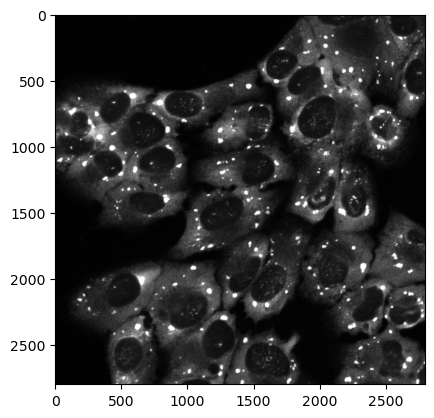

In [ ]:
import matplotlib.pyplot as plt

# Select the first time point, second channel, and first Z plane (0-based indices)
plane = data.isel(T=0, C=1, Z=0)

# Calculate the 1st and 99th percentile intensities to set the display contrast
vmin, vmax = np.percentile(plane, (1, 99))

# Display the plane in grayscale using these contrast limits
plt.imshow(plane, cmap="gray", vmin=vmin, vmax=vmax)

Now let's display all the channels of the image in a subplot using a `for` loop:

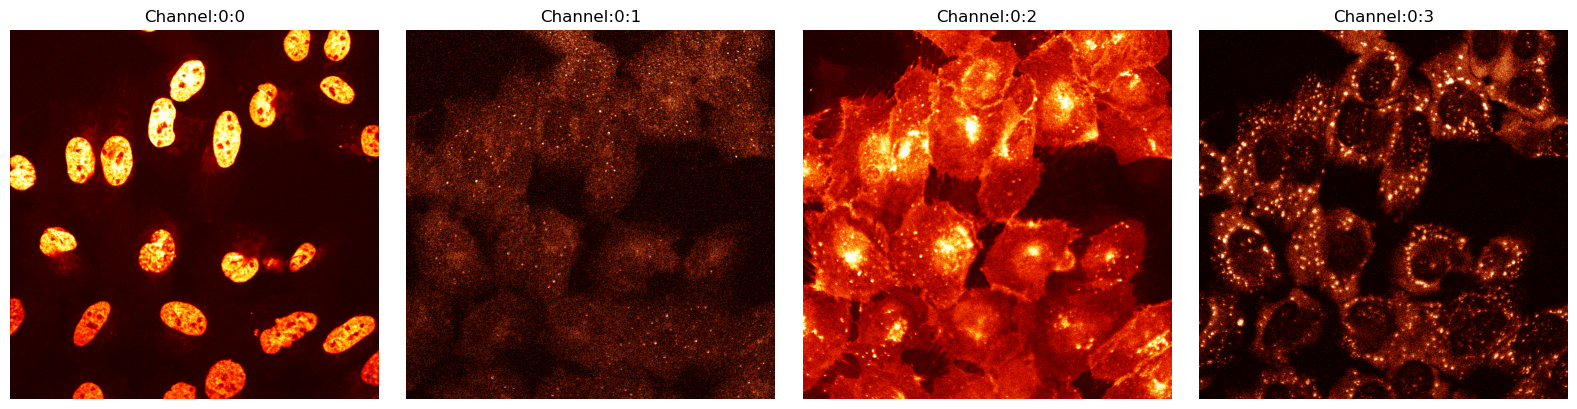

In [ ]:
import matplotlib.pyplot as plt

# Get the number of channels using the named channel dimension
num_channels = data.sizes["C"]

# Create one subplot per channel
fig, axes = plt.subplots(1, num_channels, figsize=(4 * num_channels, 4))

# Ensure axes is iterable even when there is only one channel
axes = np.atleast_1d(axes)

# Loop over each channel index and its corresponding subplot
for k, ax in enumerate(axes):
    # Select the first time point and first Z plane for this channel
    plane = data.isel(T=0, C=k, Z=0)

    # Calculate contrast limits separately for each channel
    vmin, vmax = np.percentile(plane, (1, 99))

    # Display the plane using the "hot" colormap and calculated contrast limits
    ax.imshow(plane, cmap="hot", vmin=vmin, vmax=vmax)

    # Hide the axes and ticks
    ax.set_axis_off()

    # Use the channel name as the subplot title
    ax.set_title(image.channel_names[k])

# Adjust spacing to prevent subplot overlap
plt.tight_layout()

# Show the figure
plt.show()
  

In the following cell, we crop a part of the image, display it in a figure and overlay the pixel values.

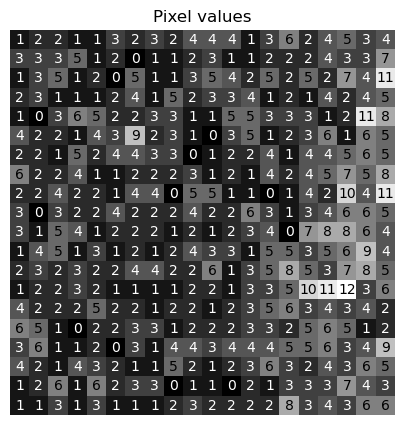

In [41]:
# Crop and take every fifth pixel
crop = data.isel(
    T=0,
    C=2,
    Z=0,
    Y=slice(850, 950, 5),
    X=slice(900, 1000, 5),
)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(crop, cmap="gray")

values = crop.values

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        c = "white" if values[i, j] < 5 else "black"
        ax.text(
            j, i, str(int(values[i, j])),
            color=c, ha="center", va="center", size=10,
        )

ax.axis("off")
ax.set_title("Pixel values")
plt.show()

### Plot with matplotlib

Let say we would like to visualize the profile of the intensity distribution of a given channel along the x-axis at the mid-position of the y-axis in the image. 

Text(0.5, 1.0, 'Intensity for channel 4')

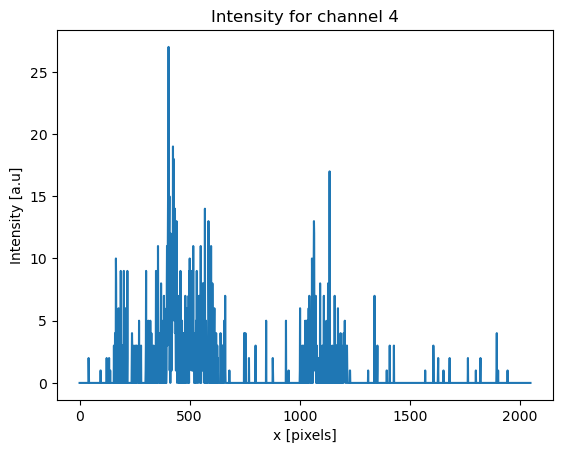

In [ ]:
int = data.isel(T=0, C=k, Z=0, Y =956) # select the intensity to display
x = np.arange(0, len(int))    # set the x-range

plt.plot(x, int)
plt.xlabel("x [pixels]")
plt.ylabel("Intensity [a.u]")
plt.title("Intensity for channel " + str(c+1))

<div class="alert alert-success">
       
#### Exercise 

To split the channels into layers, we need to specify the channel axis.

1. Add `channel_axis=1` into the add_image function in the previous cell and observe the difference from the previous viewer. 
2. Select a channel and play with the gamma or/and contrast limits parameters to adjust the contrast of each of the channel. 
3. The blending is by default additive. Select Channel 2 (dots) and set its blending to opaque. Hide and show this channel and observe the difference.
    
</div>

Now we will try to code the actions that one can manually do on the viewer.

<div class="alert alert-success">
       
#### Exercise 
    
Use the same viewer as before or create a new one. We will display the name of the channels as set in the metadata and set the contrast limits as the minimal and maximal intensity values.

1. set the `name` property to be the image.channel_names or an user-defined list of channels names,
2. create a list of min and max intensity value for the 4 channels,
3. set the `contrast_limits` property of each channel to range between the min and max intensity by attributing the `contrast_limits` variable to the created list in step 2,

Hint: use np.min(data[:, n, :, :, :]) and np.max(data[:, n, :, :, :]) to find the min and max of the n-th channel respectively
    
</div>

In [ ]:
import numpy as np

contrast_limits = [[np.min(data[:, n, :, :, :]), np.max(data[:, n, :, :, :])] for n in np.arange(data.shape[1])]
contrast_limits

### Add points layer 

Points are another types of layers that one can add to a napari viewer. It requires the coordinates of the points, (x, y) for 2D data points and (x, y, z) for 3D data points.

In the display, we will introduce the `colormap` of the labels and visibility `visible` parameters to the list of label properties.

For a label layer, the colormap needs to be in a dictionary format such that the region IDs are the keys and the RGB triplet code colors are the values. 

The dictionary key and the corresponding value of any label that is not in the list of region IDs or not of interest in the display need to be indicated by None in the colormap dictionary.

In [ ]:
# specify the colors of the labels in a dictionary
cols = {0: [0,0,0], 1: [1,0,0], 2:[0,1,0], None: None} # label 0 is reserved for the background

# Turn the visibility of the previous labels_data off
viewer.layers["labels_data"].visible = False

# Add to viewer
viewer.add_labels(labels_data, name="My labels", opacity=0.5, colormap=cols, visible=True)

## Segment the cell using CellPose (Deep Learning approach)

Image segmentation is the process of partitioning an image into multiple distinct regions. In semantic segmentation, regions can represent objects of interests against background. They can then be represented as a binary mask. Several type of objects can be further encoded using a label image. Finally, instance segmentation aims at distinguishing different identities of objects of potentially the same class and can also be represented using a label image.

[Cellpose](https://cellpose.readthedocs.io/en/latest/) is a generalist cellular segmentation algorithm, trained on diverse datasets that works on wide a range of data types.

Key features: 
- Instance segmentation
- Easy-to-use GUI
- A “zoo” of pre-trained models
- Well-documented Python API
- Simple fine-tuning of models via Human-in-the-Loop retraining


<img src="../ressources/cellpose_w.png" alt="drawing" width="800"/>


## Steps
- Get the pretrained model using models.CellposeModel
- Apply the model for segmentation using model.eval
  - Parameters:
    - img : np.ndarray, input image to segment.
    - channels : list of int, specifies which channels to use from the image:
      - channels[0]: channel to segment (e.g. cytoplasmic)
      - channels[1]: optional auxiliary channel (e.g. nuclear)
    - diameter : float or int, a user-defined cell diameter (in pixels) or an estimated one when set "diameter = None" or "diameter = 0". It is used to rescale the image internally to match the training conditions of the model. 
    - cellprob_threshold : float, threshold applied to the internal "cell probability" map output by the model. Higher values result in stricter segmentation. Typical range: 0.0 to 1.0
  - Returns:
    - mask : np.ndarray, segmentation mask with labeled regions.
    - flows : list of np.ndarray, list of flow-related outputs used in Cellpose for segmentation and visualization.
      - flows[0]: HSV-encoded XY flow image (H, W, 3), for visualization only.
      - flows[1]: Raw XY flow vectors (2, H, W), directing pixel movement toward cell centers.
      - flows[2]: Cell probability map (H, W); used to threshold foreground pixels.
      - flows[3]: Final pixel coordinates after Euler integration (2, H, W); used to define cell masks.
    - diams : float, estimated object diameter based on image content (may differ from input diameter).


## Check for GPU Availability
Checks for a CUDA-compatible GPU, which significantly accelerates deep learning model training and inference.

In [62]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

use_gpu = torch.cuda.is_available()

2.8.0
None
False


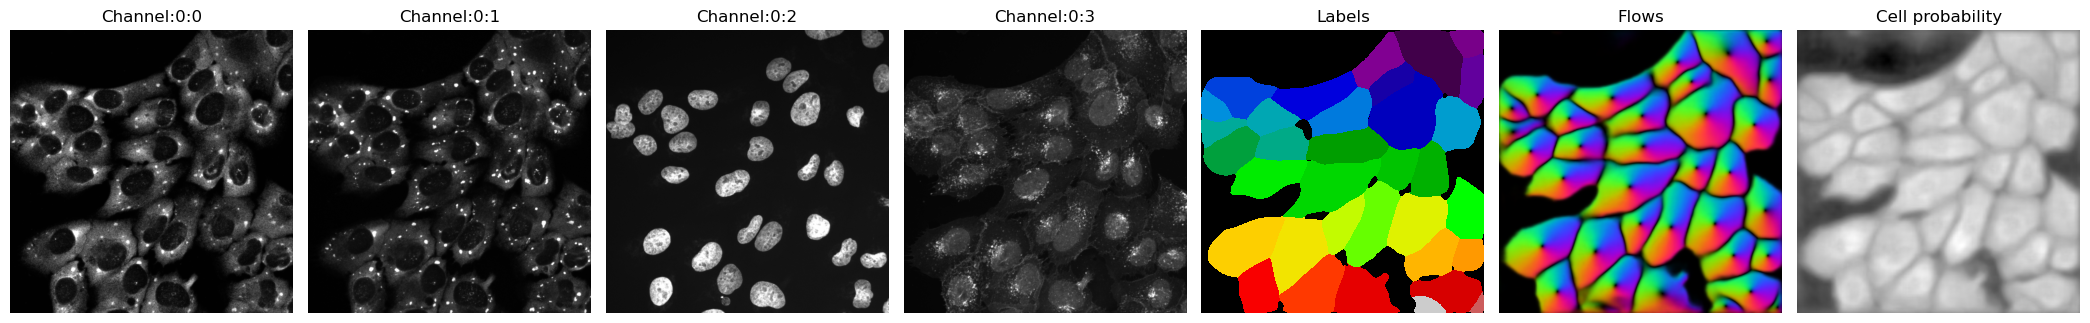

In [64]:
from cellpose import models
import matplotlib.pyplot as plt

# Select a 2D multichannel image: (C, Y, X)
plane = data.isel(T=0, Z=0)

# Cellpose v3: pretrained cyto2 model
model = models.CellposeModel(gpu=use_gpu, model_type="cyto2")

# Cellpose channel numbers: 1 = nuclei channel, 3 = membrane channel
masks, flows, styles = model.eval(
    plane.values,
    channel_axis=0,
    channels=[4, 3],
    diameter=400,
    cellprob_threshold=1.0,
)

# Display channels and segmentation results
num_channels = plane.sizes["C"]
fig, axes = plt.subplots(
    1, num_channels + 3,
    figsize=(3 * (num_channels + 3), 4),
)

for k in range(num_channels):
    axes[k].imshow(plane.isel(C=k), cmap="gray")
    axes[k].set_axis_off()
    axes[k].set_title(image.channel_names[k])

axes[num_channels].imshow(masks, cmap="nipy_spectral", interpolation="nearest")
axes[num_channels].set_title("Labels")

axes[num_channels + 1].imshow(flows[0])
axes[num_channels + 1].set_title("Flows")

axes[num_channels + 2].imshow(flows[2], cmap="gray")
axes[num_channels + 2].set_title("Cell probability")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## Display with napari viewer

Napari is an interactive Python tool for viewing scientific images. It allows users to visualize 2D, 3D, and higher-dimensional data on a single canvas, overlay derived data like points and segmentations, and seamlessly integrate exploration with computation and annotation.

Similar to Fiji, we can also hide or show some channels using what is called `layer` in the viewer. The layer can have properties such as `name`, `opacity`, `blending`, etc. 


## Add labels layer

A label layer is an image-like layer where every pixel contains an integer ID corresponding to the region it belongs to. 

To illustrate this, we will create a labels data of the same size as the 2D image channel.  

In [65]:
import napari

viewer = napari.Viewer()

# add the images, one channel per layer
viewer.add_image(
    data.values,
    channel_axis=data.get_axis_num("C"),
    name=image.channel_names,
)

# add the cellpose masks
viewer.add_labels(masks)

<Labels layer 'masks' at 0x360e8ba60>

## Localize the stress granules with spot detection

In [ ]:
from skimage import feature
import pandas as pd

stress_g = data.isel(T=0, C=0, Z=0)

# detect blobs
blobs = feature.blob_log(stress_g, min_sigma=2, max_sigma=10, threshold=0.01)